# Самостоятельная работа. О чём пишут в коротких новостях

**Тема:** тематическое моделирование (лекция 3). **Данные:** короткие новости Lenta.ru из файла `data/lenta_ru_short.jsonl`: заголовок и два-три предложения текста. У каждой новости есть рубрика редакции.

## Цель

Построить тематическую модель по коротким новостям и проверить, совпадают ли найденные темы с рубриками редакции. Модель рубрик не видит: они нужны только для проверки. В конце по теме новости предсказывается её рубрика, и результат сравнивается с обычным классификатором.

## План

| Часть | Содержание |
|---|---|
| 1 | Корпус и предобработка |
| 2 | Модель LDA: темы и профили новостей |
| 3 | Задания для самостоятельного решения |

Части 1 и 2 разобраны полностью. В части 3 шесть заданий с самопроверкой.

## Обозначения

- $\phi_{wk}=p(w\mid k)$ обозначает вероятность слова $w$ в теме $k$, матрица $\Phi$ хранит темы.
- $\theta_{kd}=p(k\mid d)$ обозначает долю темы $k$ в документе $d$, матрица $\Theta$ хранит профили документов.
- $K$ обозначает число тем. Документом служит одна новость.

In [1]:
import json
import re
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")
SEED = 42
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MUTED, GRID = "#6b7280", "#e5e7eb"
SEQ = LinearSegmentedColormap.from_list("seq", ["#f6f9fe", "#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold"})

## Часть 1. Корпус и предобработка

В файле четыре крупные рубрики: «Спорт», «Культура», «Экономика», «Наука и техника». Данные уже разделены на обучающую и тестовую части. Модель обучается на обучающей части, тестовая понадобится в задании 6.

Предобработка та же, что на семинаре: слова приводятся к начальной форме библиотекой `pymorphy3`, стоп-слова удаляются. В словаре остаются слова, которые встретились не менее чем в 5 новостях и не более чем в 30 % новостей.

In [2]:
import pymorphy3
from gensim.corpora import Dictionary


def find_data(name):
    for parent in [Path.cwd()] + list(Path.cwd().parents):
        if (parent / "data" / name).exists():
            return parent / "data" / name
    raise FileNotFoundError(f"Файл data/{name} не найден в репозитории")


rows = [json.loads(line) for line in open(find_data("lenta_ru_short.jsonl"), encoding="utf-8")]
df = pd.DataFrame([r for r in rows if r["topic"] != "Бизнес"])          # в рубрике «Бизнес» всего семь новостей
df["full"] = df.title.str.replace("\xa0", " ") + ". " + df.text.str.replace("\xa0", " ")
train, test = df[df.split == "train"].reset_index(drop=True), df[df.split == "test"].reset_index(drop=True)
print(f"Новостей: обучение {len(train)}, тест {len(test)}")
print(train.topic.value_counts().to_string())
print("\nПример:", train.full[0][:230], "...")

try:
    from nltk.corpus import stopwords
    STOP = set(stopwords.words("russian"))
except Exception:
    STOP = set("и в во не что он на я с со как а то все она так его но да ты к у же вы за бы по только ее мне было вот от "
               "меня еще нет о из ему теперь когда даже ну ли если уже или ни быть был него до вас там потом себя ничего "
               "ей может они тут где есть надо ней для мы тебя их чем была сам без будто чего раз тоже себе под будет "
               "тогда кто этот того потому этого какой ним здесь этом один мой тем чтобы нее были куда всех можно при два "
               "об другой после над больше тот через эти нас про всего них какая много три эту перед лучше том такой им "
               "более всегда между".split())
STOP |= set('''это который весь свой год также мочь такой наш однако время сообщать сообщить заявить заявлять отметить
рассказать слово стать один два три первый новый самый другой около несколько человек день неделя месяц процент миллион
миллиард тысяча рубль доллар получить сказать говорить считать пока лишь ранее очень иметь какой любой каждый результат
часть случай место раз работа мир россия российский'''.split())

morph = pymorphy3.MorphAnalyzer()
_cache = {}


def preprocess(text):
    out = []
    for t in re.findall(r"[а-яё]+", text.lower()):
        if len(t) < 3:
            continue
        if t not in _cache:
            _cache[t] = morph.parse(t)[0].normal_form.replace("ё", "е")
        if _cache[t] not in STOP and t not in STOP:
            out.append(_cache[t])
    return out


docs = [preprocess(t) for t in train.full]
dictionary = Dictionary(docs)
size_before = len(dictionary)
dictionary.filter_extremes(no_below=5, no_above=0.3)
bow = [dictionary.doc2bow(d) for d in docs]
print(f"\nСловарь: {size_before} слов до фильтрации, {len(dictionary)} после")
print("Средняя длина новости после предобработки:", round(float(np.mean([len(d) for d in docs])), 1), "слов")

Новостей: обучение 4034, тест 447
topic
Спорт              1278
Культура           1152
Экономика           844
Наука и техника     760

Пример: Торговля в США начинает оживляться. Согласно данным министерства торговли США, в июле товарные запасы американских оптовиков снизились на 0,7 процента, что является их самым резким падением с сентября 1996 года, сообщает агентство ...

Словарь: 20971 слов до фильтрации, 4601 после
Средняя длина новости после предобработки: 42.9 слов


## Часть 2. Модель LDA

Модель обучается библиотекой gensim с восемью темами. Обучение начинается со случайного приближения, поэтому модель обучается с тремя значениями `seed` и берётся запуск с наибольшей когерентностью. Когерентность NPMI измеряет, насколько часто главные слова темы встречаются вместе. Положительное значение означает связную тему.

Когерентность NPMI по запускам: {1: 0.01, 2: 0.054, 3: 0.065}


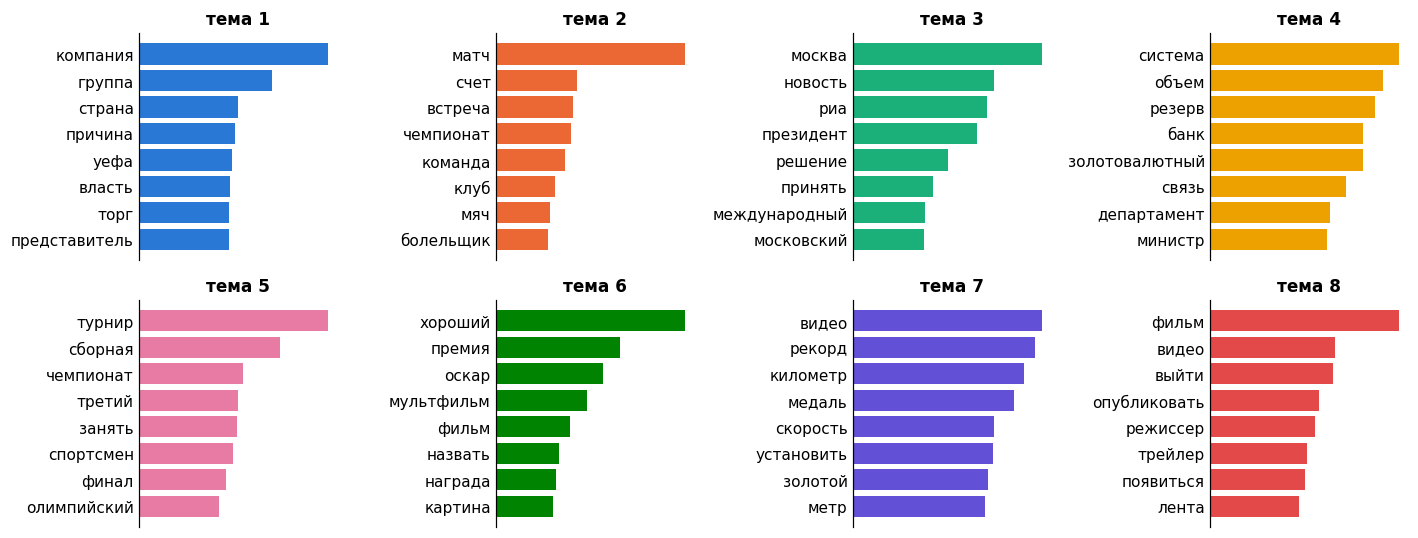

In [3]:
from gensim.models import CoherenceModel, LdaModel


def train_lda(k, seed=SEED, corpus=None, id2word=None):
    return LdaModel(corpus=bow if corpus is None else corpus, id2word=id2word or dictionary, num_topics=k,
                    random_state=seed, passes=15, chunksize=500, iterations=100, alpha="auto", eta="auto")


def get_phi(model):
    phi = model.get_topics()
    return phi / phi.sum(1, keepdims=True)


def get_theta(model, corpus=None):
    corpus = bow if corpus is None else corpus
    theta = np.zeros((len(corpus), model.num_topics))
    for i, b in enumerate(corpus):
        for k, p in model.get_document_topics(b, minimum_probability=0):
            theta[i, k] = p
    return theta


def top_words(phi, k, n=10, id2word=None):
    id2word = id2word or dictionary
    return [id2word[i] for i in np.argsort(phi[k])[::-1][:n]]


def npmi(topics, texts=None, id2word=None):
    # когерентность списка тем; тема задаётся списком своих главных слов
    return CoherenceModel(topics=topics, texts=texts or docs, dictionary=id2word or dictionary, coherence="c_npmi",
                          topn=10).get_coherence()


K = 8
runs = {s: train_lda(K, seed=s) for s in (1, 2, 3)}
scores = {s: npmi([top_words(get_phi(m), k) for k in range(K)]) for s, m in runs.items()}
print("Когерентность NPMI по запускам:", {s: round(v, 3) for s, v in scores.items()})
lda = runs[max(scores, key=scores.get)]
phi, theta = get_phi(lda), get_theta(lda)


def plot_topics(phi, id2word=None, n_words=8):
    id2word = id2word or dictionary
    fig, axes = plt.subplots(2, 4, figsize=(13, 5))
    for k, ax in enumerate(axes.ravel()):
        if k >= phi.shape[0]:
            ax.axis("off"); continue
        order = np.argsort(phi[k])[::-1][:n_words][::-1]
        ax.barh([id2word[i] for i in order], phi[k, order], color=CAT[k % len(CAT)])
        ax.set_title(f"тема {k + 1}"); ax.set_xticks([]); ax.spines["bottom"].set_visible(False); ax.tick_params(axis="y", length=0)
    fig.tight_layout()
    plt.show()


plot_topics(phi)

**Что видно на рисунке.** Каждая панель показывает восемь самых вероятных слов одной темы. Часть тем читается сразу. Модель возвращает только распределения, названия темам даёт человек: это задание 2.

Профиль новости показывает, из каких тем она состоит. Ниже профили шести новостей.

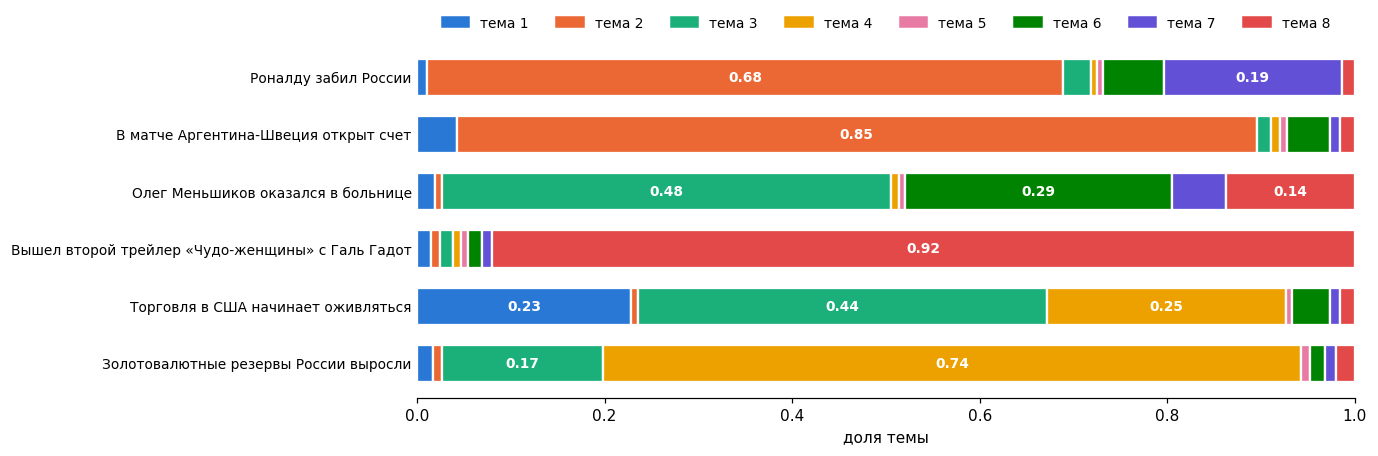

In [4]:
def show_profiles(indices, theta_matrix=None, titles=None):
    th = theta if theta_matrix is None else theta_matrix
    titles = train.title if titles is None else titles
    fig, ax = plt.subplots(figsize=(11, 0.5 * len(indices) + 1.2))
    for row, i in enumerate(indices[::-1]):
        left = 0
        for k in range(th.shape[1]):
            ax.barh(row, th[i, k], left=left, color=CAT[k % len(CAT)], edgecolor="white", linewidth=1.5, height=0.65)
            if th[i, k] > 0.08:
                ax.text(left + th[i, k] / 2, row, f"{th[i, k]:.2f}", ha="center", va="center", color="white", fontsize=9,
                        fontweight="bold")
            left += th[i, k]
    ax.set_yticks(range(len(indices))); ax.set_yticklabels([str(titles[i]).replace("\xa0", " ")[:60] for i in indices[::-1]], fontsize=9)
    ax.set_xlim(0, 1); ax.set_xlabel("доля темы"); ax.tick_params(axis="y", length=0); ax.spines["left"].set_visible(False)
    ax.legend([plt.Rectangle((0, 0), 1, 1, color=CAT[k % len(CAT)]) for k in range(th.shape[1])],
              [f"тема {k + 1}" for k in range(th.shape[1])], ncol=th.shape[1], loc="lower center", bbox_to_anchor=(0.5, 1.0),
              frameon=False, fontsize=9)
    plt.show()


sample = [int(train.index[train.topic == r][j]) for r in ("Спорт", "Культура", "Экономика") for j in (0, 1)]
show_profiles(sample)

**Что видно на рисунке.** У короткой новости обычно одна преобладающая тема: в двух-трёх предложениях редко помещаются два предмета. Этим короткие тексты отличаются от длинных новостей семинара.

## Часть 3. Задания для самостоятельного решения

Замените многоточия своим кодом. После каждого задания запишите вывод в одну-две фразы. В заданиях используются объекты из частей 1 и 2: `train`, `test`, `docs`, `dictionary`, `bow`, `lda`, `phi`, `theta`, функции `preprocess`, `train_lda`, `get_phi`, `get_theta`, `top_words`, `npmi`, `plot_topics`, `show_profiles`.

### Задание 1. Слова агентств

1. Найдите 20 слов, которые встречаются в наибольшем числе новостей обучающей части (после предобработки).
2. Среди главных слов тем есть слова «новость», «риа», «интерфакс», «передавать». Они попадают в текст из ссылок на источник и о предмете новости не сообщают. Добавьте их в список `STOP`, повторите предобработку, постройте словарь и обучите модель заново (`seed` тот же, что у модели `lda`). Сохраните результат в `docs2`, `dictionary2`, `bow2`, `lda2`.
3. Сравните главные слова тем двух моделей.

**Самопроверка.** В главных словах тем новой модели слов агентств нет. Когерентность двух моделей различается меньше чем на 0.05.

In [ ]:
doc_freq = Counter(w for d in docs for w in set(d))
print(...)

STOP |= {...}
docs2 = ...
dictionary2 = ...
bow2 = ...
lda2 = ...
plot_topics(get_phi(lda2), id2word=dictionary2)

### Задание 2. Названия тем

Для каждой темы модели `lda` выведите десять главных слов и три новости с наибольшей долей этой темы (доля и заголовок). Дайте каждой теме короткое название и запишите названия в список `topic_names`.

**Самопроверка.** У большинства тем главные слова и заголовки относятся к одному предмету. Если тема соединяет два предмета, укажите оба.

In [ ]:
for k in range(K):
    print(f"Тема {k + 1}:", ...)
    ...

topic_names = ["...", "...", "...", "...", "...", "...", "...", "..."]

### Задание 3. Темы и рубрики

1. Постройте таблицу: строка соответствует рубрике, столбец теме, в клетке стоит средняя доля темы в новостях рубрики. Покажите её тепловой картой.
2. Преобладающей темой новости называется тема с наибольшей долей. Сопоставьте каждой теме рубрику, новости которой чаще всего имеют эту тему преобладающей. Сохраните соответствие в массив `topic_rubric` длины $K$.
3. Посчитайте согласие с рубриками: долю обучающих новостей, у которых рубрика совпала с рубрикой их преобладающей темы.

**Самопроверка.** Согласие лежит между 0.65 и 0.85. У рубрики «Спорт» есть тема со средней долей больше 0.3.

In [ ]:
rubrics = ["Спорт", "Культура", "Экономика", "Наука и техника"]
M = ...                                  # матрица рубрики x темы
...

dominant = theta.argmax(1)
topic_rubric = ...
agreement = ...
print(agreement)

### Задание 4. LDA и NMF

Неотрицательное матричное разложение (NMF) раскладывает матрицу весов TF-IDF в произведение двух неотрицательных матриц. Строки второй матрицы читаются как темы, первая матрица даёт веса тем в документах.

1. Постройте матрицу TF-IDF обучающих новостей по словарю `dictionary` и обучите `NMF(n_components=8, init="nndsvda", random_state=SEED, max_iter=400)`.
2. Выведите главные слова восьми тем NMF.
3. Посчитайте для NMF когерентность NPMI и согласие с рубриками (как в задании 3) и сравните с LDA.

**Самопроверка.** Когерентность NMF выше, чем у LDA, не менее чем на 0.05. Согласие с рубриками у двух моделей различается меньше чем на 0.1.

In [ ]:
from gensim.matutils import corpus2csc
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfTransformer

N = corpus2csc(bow, num_terms=len(dictionary)).T.tocsr()        # матрица новости x слова
X = ...
nmf = ...
...

### Задание 5. Число тем

Обучите LDA с числом тем 4, 8 и 16 (`seed=1`). Для каждой модели посчитайте когерентность NPMI и согласие с рубриками. Постройте два графика.

Рубрик четыре. Почему согласие не достигает максимума при четырёх темах? Что происходит с рубриками при 16 темах: выведите главные слова тем, отнесённых к рубрике «Спорт».

**Самопроверка.** Согласие с рубриками при 16 темах не ниже, чем при 4 темах. При 16 темах рубрика «Спорт» представлена несколькими темами.

In [ ]:
for k in (4, 8, 16):
    m = train_lda(k, seed=1)
    ...

### Задание 6. Рубрика по теме

Тематическую модель можно использовать как классификатор: новости приписывается рубрика её преобладающей темы.

1. Напишите функцию `predict_rubric(texts)`. Она обрабатывает тексты функцией `preprocess`, получает профили тем по модели `lda` и возвращает для каждого текста рубрику преобладающей темы (массив `topic_rubric` из задания 3).
2. Посчитайте долю верных ответов на тестовых новостях `test`.
3. Сравните с обычным классификатором: `TfidfVectorizer` и `LogisticRegression(C=10, max_iter=1000)`, обученными на исходных текстах обучающей части.
4. Проверьте функцию на трёх своих заголовках.

**Самопроверка.** Доля верных ответов по теме лежит между 0.6 и 0.85. Логистическая регрессия на TF-IDF точнее не менее чем на 0.1. Объясните, почему обученный без рубрик метод уступает и в каких случаях он всё же полезен.

In [ ]:
def predict_rubric(texts):
    ...


acc_topics = ...
print(acc_topics)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
...

## Что сдавать

Блокнот, который выполняется целиком без ошибок, с решениями шести заданий и выводами.

- [ ] Рубрики не используются при обучении тематической модели, только при проверке.
- [ ] Тестовые новости не участвуют в обучении ни одной модели.
- [ ] Названия тем даны после чтения главных слов и новостей с наибольшей долей темы.
- [ ] Значение `seed` зафиксировано, результат воспроизводится.
- [ ] К каждому заданию записан вывод со ссылкой на полученные числа.